### Step 0: Getting Started
## 1. Project Objective
The objective of this project is to develop and evaluate a Support Vector Regression (SVR) model to predict fish body mass using fish measurements and environmental variables.

## 2. Dataset Description
The project uses two datasets:
- **Fish information:** contains fish characteristics, including species, length, and mass.
- **Stream information:** contains environmental characteristics of the sites where fish were collected.

The two datasets are linked using the `Code_ID` column.

## 3. Prediction Task
- **Task:** Regression
- **Assigned model:** Support Vector Regression (SVR)
- **Baseline model:** Dummy Regressor using the mean strategy
- **Target variable:** Logarithm of fish mass (`ln(Mass_g)`)

## 4. Data Splitting
The project uses site-based grouping to avoid data leakage. Fish collected from the same site should be considered together during validation.

## 5. Reproducibility
The random seed is set to `42` to ensure reproducibility.

In [15]:
# ==========================================
# STEP 0: GETTING STARTED
# ==========================================

# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# 2. Set random seed

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 3. Define project paths

DATA_DIR = Path("../Data")

# 4. Check dataset directory

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Data directory not found: {DATA_DIR.resolve()}")

print("Imports completed successfully.")
print("Random state:", RANDOM_STATE)
print("Data directory:", DATA_DIR.resolve())

print("\nDataset files:")

for file in sorted(DATA_DIR.iterdir()):
    print("-", file.name)

Imports completed successfully.
Random state: 42
Data directory: C:\Users\work\Desktop\SVR_Model\Data

Dataset files:
- 0_Data_Dictionary.txt
- 1_stream_information.txt
- 2_fish_information.txt
- README.md


## Read Dataset Documentation 

In [16]:
# ==========================================
# STEP 0: DATASET DOCUMENTATION
# ==========================================

# Read the data dictionary

data_dictionary = pd.read_csv(
    DATA_DIR / "0_Data_Dictionary.txt",
    sep="\t",
    encoding="latin-1"
)

print("DATA DICTIONARY")
print("Shape:", data_dictionary.shape)

display(data_dictionary)

# Preview the README file

readme_path = DATA_DIR / "README.md"

if readme_path.exists():
    print("\nDATASET README")
    print("=" * 60)

    with open(readme_path, "r", encoding="utf-8") as file:
        print(file.read())

DATA DICTIONARY
Shape: (23, 5)


,Variable name,Description,Units,Variable type,Excel Spreedsheet
0,Code_ID,Unique number identifying a stream location,Unitless,Categorical,1_stream_information; 2_fish_information
1,Stream,Name of the stream,Unitless,String,1_stream_information; 2_fish_information
2,Location,Name of the location,Unitless,String,1_stream_information; 2_fish_information
3,Lat_degree,Latitudinal coordinates in WGS 84,Degree,Numeric,1_stream_information
4,Long_degree,Longitudinal coordinates in WGS 84,Unitless,Numeric,1_stream_information
5,Source,Source of the public administration where the ...,Unitless,String,1_stream_information
6,Day,Day of the fish sampling,Day,Numeric,1_stream_information
7,Month,Month of the fish sampling,Month,Numeric,1_stream_information
8,Year,Year of the fish sampling,Year,Numeric,1_stream_information
9,Fish_number,Total number of fish caught in each stream loc...,Individuals,Numeric,1_stream_information



DATASET README
# Arranz.et.al.DiB.2022
Individual body size data of stream fish in the Iberian Peninsula

Summary:

This data contains three files

- data dictionary: 0_Data_Dictionary 
- environmental data: 1_stream_information 
- fish data: 2_fish_information

The files 1_stream_information and 2_fish_information can be concatenated according to the variable 
in both spreadsheets named Code_ID, which consists of a numeric sequence of values from 1 to 118.



## Load and Inspect Raw Datasets
## Dataset Description
STREAM DATA
Shape: (118, 17)
FISH DATA
Shape: (12288, 9)
Number of unique sites: 118
Number of unique species: 24
Number of fish records: 12288

In [17]:
# ==========================================
# STEP 0: LOAD RAW DATASETS
# ==========================================

# Load stream information

stream_data = pd.read_csv(
    DATA_DIR / "1_stream_information.txt",
    sep="\t",
    encoding="latin-1"
)

# Load fish information

fish_data = pd.read_csv(
    DATA_DIR / "2_fish_information.txt",
    sep="\t",
    encoding="latin-1"
)

# Inspect stream dataset

print("STREAM DATA")
print("Shape:", stream_data.shape)
print("Columns:", stream_data.columns.tolist())

display(stream_data.head())

# Inspect fish dataset

print("\nFISH DATA")
print("Shape:", fish_data.shape)
print("Columns:", fish_data.columns.tolist())

display(fish_data.head())

# Check unique sites and species

print("\nNumber of unique sites:", fish_data["Code_ID"].nunique())

print("Number of unique species:", fish_data["Scientific_name"].nunique())

print("Number of fish records:", len(fish_data))

STREAM DATA
Shape: (118, 17)
Columns: ['Code_ID', 'Stream', 'Location', 'Lat_degree', 'Long_degree', 'Source', 'Day', 'Month', 'Year', 'Fish_number', 'SA_m2', 'TP_mg.l', 'TN_mg.l', 'Temp_degree_celcius', 'Prec_mm', 'Alt_m', 'IMPRESS']


,Code_ID,Stream,Location,Lat_degree,Long_degree,Source,Day,Month,Year,Fish_number,SA_m2,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
0,1,Ebro,Miranda de Ebro,42.687282,-2.954187,CHE,18,10,2007,74,698.0,0.10,8.38,12.5,727,454.68,2.00
1,2,Arga,Funes,42.301003,-1.789143,CHE,8,7,2007,143,415.0,0.24,10.93,13.6,576,279.10,10.50
2,3,Aragon,Caparroso,42.344712,-1.650659,CHE,27,8,2007,70,575.0,0.10,8.35,13.4,625,300.01,10.65
3,4,Martin,Hijar,41.173897,-0.456685,CHE,25,10,2007,68,358.0,0.13,13.10,14.6,371,294.61,10.75
4,5,Guadalope,Alcaniz,40.932767,-0.196697,CHE,24,10,2006,54,887.0,0.11,10.33,14.3,431,383.92,10.25



FISH DATA
Shape: (12288, 9)
Columns: ['Code_ID', 'Stream', 'Location', 'Family', 'Genus', 'Species', 'Scientific_name', 'Length_mm', 'Mass_g']


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g
0,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,442,1700.0
1,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,405,1220.0
2,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,373,1040.0
3,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,199,139.9
4,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,225,133.0



Number of unique sites: 118
Number of unique species: 24
Number of fish records: 12288


# Step 1: Data Exploration (EDA)

Exploratory Data Analysis (EDA) is performed to understand the structure and quality of the dataset before building the machine learning model.

### 1. Dataset Structure and Data Quality
This section examines the dimensions, variable types, measurement units, missing values, duplicate records, and potential outliers in the fish and stream datasets.

Descriptive statistics and the IQR method are used to investigate the numerical variables. Duplicate records and extreme values are examined without automatically removing any observations.

1. DATASET DIMENSIONS
Fish dataset: (12288, 9)
Stream dataset: (118, 17)

2. VARIABLE TYPES

Fish dataset:


Code_ID              int64
Stream                 str
Location               str
Family                 str
Genus                  str
Species                str
Scientific_name        str
Length_mm            int64
Mass_g             float64
dtype: object


Stream dataset:


Code_ID                  int64
Stream                     str
Location                   str
Lat_degree             float64
Long_degree            float64
Source                     str
Day                      int64
Month                    int64
Year                     int64
Fish_number              int64
SA_m2                  float64
TP_mg.l                float64
TN_mg.l                float64
Temp_degree_celcius    float64
Prec_mm                  int64
Alt_m                  float64
IMPRESS                float64
dtype: object


3. MISSING VALUES

Fish dataset:


Code_ID            0
Stream             0
Location           0
Family             0
Genus              0
Species            0
Scientific_name    0
Length_mm          0
Mass_g             0
dtype: int64

... (3 outputs left out)

,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g
29,1,Ebro,Miranda de Ebro,Cyprinidae,Gobio,lozanoi,Gobio lozanoi,75,5.8
30,1,Ebro,Miranda de Ebro,Cyprinidae,Gobio,lozanoi,Gobio lozanoi,75,5.8
31,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,78,5.7
32,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,78,5.7
53,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,62,2.9
54,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,62,2.9
68,1,Ebro,Miranda de Ebro,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,39,0.6
69,1,Ebro,Miranda de Ebro,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,39,0.6
74,2,Arga,Funes,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,32,0.3
79,2,Arga,Funes,Leuciscidae,Achondrostoma,arcasii,Achondrostoma arcasii,28,0.2



5. NUMERICAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Length_mm,12288.0,99.342855,74.036214,15.00,56.00,77.00,115.000,862.00
Mass_g,12288.0,45.725521,180.627982,0.10,2.00,5.60,18.925,4500.00
TP_mg.l,12288.0,0.185877,0.341485,0.05,0.09,0.10,0.140,3.16
TN_mg.l,12288.0,8.667321,9.585847,0.50,2.20,5.58,12.350,60.24
Temp_degree_celcius,12288.0,12.684774,1.679748,6.90,11.70,12.90,13.700,16.40
Prec_mm,12288.0,634.870687,188.147054,349.00,490.00,581.00,767.000,1175.00
Alt_m,12288.0,483.779501,211.172105,86.21,322.84,470.93,613.290,1293.66
IMPRESS,12288.0,6.920002,3.183545,0.41,3.83,7.50,10.000,12.00



6. POTENTIAL OUTLIERS


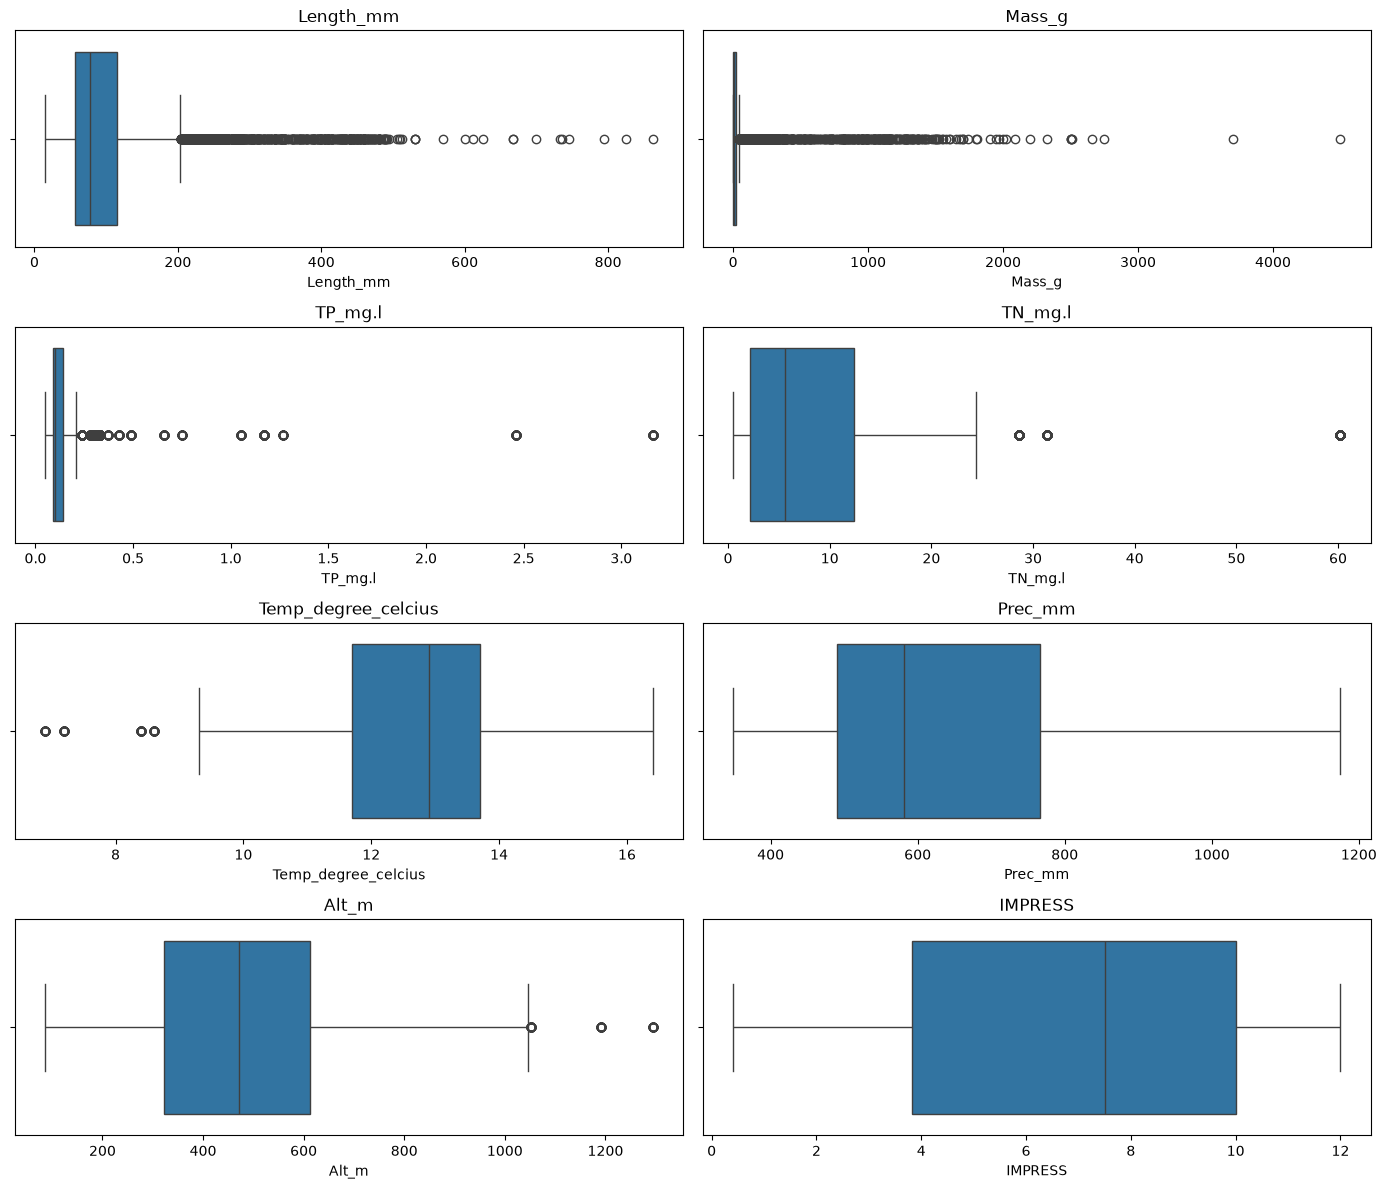


7. IQR OUTLIER ANALYSIS


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers
0,Length_mm,56.00,115.000,59.000,-32.5000,203.5000,883
1,Mass_g,2.00,18.925,16.925,-23.3875,44.3125,1715
2,TP_mg.l,0.09,0.140,0.050,0.0150,0.2150,2106
3,TN_mg.l,2.20,12.350,10.150,-13.0250,27.5750,471
4,Temp_degree_celcius,11.70,13.700,2.000,8.7000,16.7000,219
5,Prec_mm,490.00,767.000,277.000,74.5000,1182.5000,0
6,Alt_m,322.84,613.290,290.450,-112.8350,1048.9650,167
7,IMPRESS,3.83,10.000,6.170,-5.4250,19.2550,0


In [29]:
# ==============================================
# STEP 1: DATA STRUCTURE AND DATA QUALITY
# ==============================================

# 1. Dataset dimensions
print("=" * 60)
print("1. DATASET DIMENSIONS")
print("=" * 60)

print("Fish dataset:", fish_data.shape)
print("Stream dataset:", stream_data.shape)


# 2. Variable types
print("\n" + "=" * 60)
print("2. VARIABLE TYPES")
print("=" * 60)

print("\nFish dataset:")
display(fish_data.dtypes)

print("\nStream dataset:")
display(stream_data.dtypes)


# 3. Missing values
print("\n" + "=" * 60)
print("3. MISSING VALUES")
print("=" * 60)

print("\nFish dataset:")
display(fish_data.isnull().sum())

print("\nStream dataset:")
display(stream_data.isnull().sum())


# 4. Duplicate records
print("\n" + "=" * 60)
print("4. DUPLICATE RECORDS")
print("=" * 60)

fish_duplicates = fish_data.duplicated().sum()
stream_duplicates = stream_data.duplicated().sum()

print("Fish duplicate rows:", fish_duplicates)
print("Stream duplicate rows:", stream_duplicates)

duplicate_records = fish_data[
    fish_data.duplicated(keep=False)
]

print("\nRows involved in fish duplicates:",
      len(duplicate_records))

print("\nExamples of duplicated fish records:")
display(duplicate_records.head(10))


# 5. Measurement units and descriptive statistics
print("\n" + "=" * 60)
print("5. NUMERICAL DESCRIPTIVE STATISTICS")
print("=" * 60)

numerical_columns = [
    "Length_mm",
    "Mass_g",
    "TP_mg.l",
    "TN_mg.l",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "IMPRESS"
]

display(data[numerical_columns].describe().T)


# 6. Potential outliers using boxplots
print("\n" + "=" * 60)
print("6. POTENTIAL OUTLIERS")
print("=" * 60)

plt.figure(figsize=(14, 12))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(x=data[column])
    plt.title(column)

plt.tight_layout()
plt.show()


# 7. IQR outlier detection
print("\n" + "=" * 60)
print("7. IQR OUTLIER ANALYSIS")
print("=" * 60)

outlier_results = []

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    outlier_results.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

### 1.2 Distributions of Variables and Correlation Analysis
The distributions of numerical and categorical variables are examined to understand the characteristics of the fish dataset.

Histograms are used to visualize numerical variables, while bar plots are used to examine categorical variables, particularly fish species.

A correlation matrix and heatmap are used to investigate the strength and direction of linear relationships between numerical variables and the target variable (`Mass_g`).

1. DISTRIBUTIONS OF NUMERICAL VARIABLES


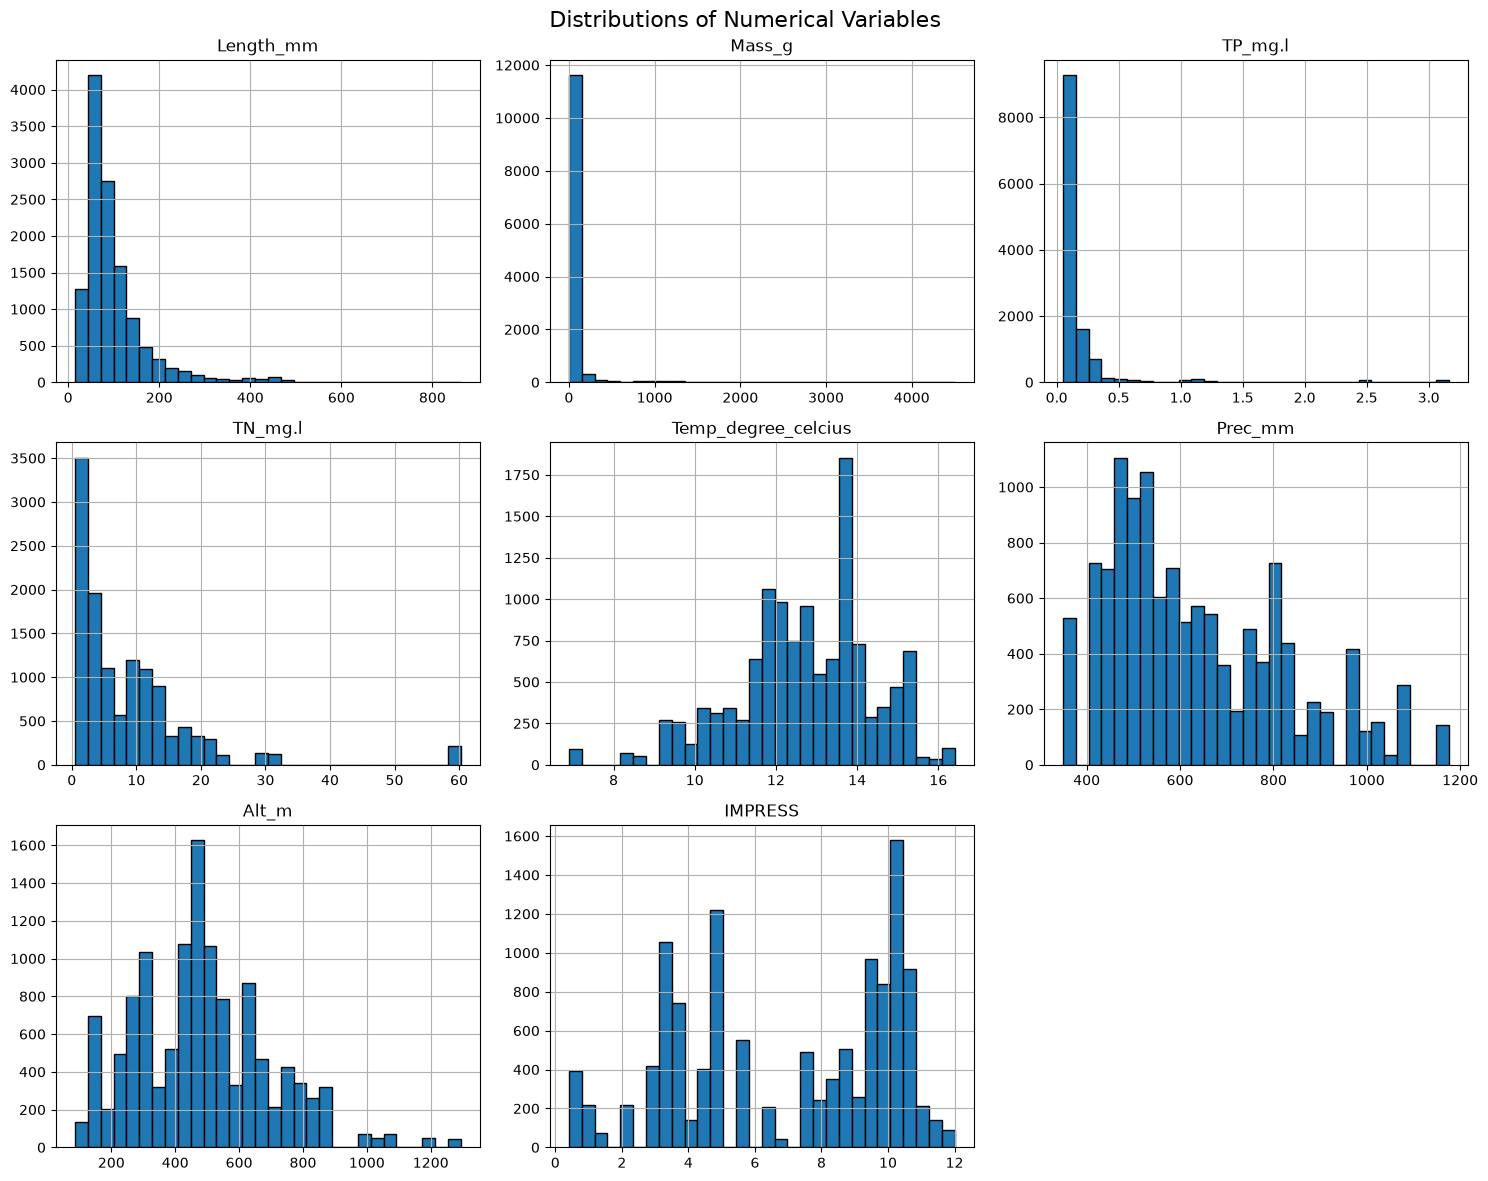


2. DISTRIBUTIONS OF CATEGORICAL VARIABLES


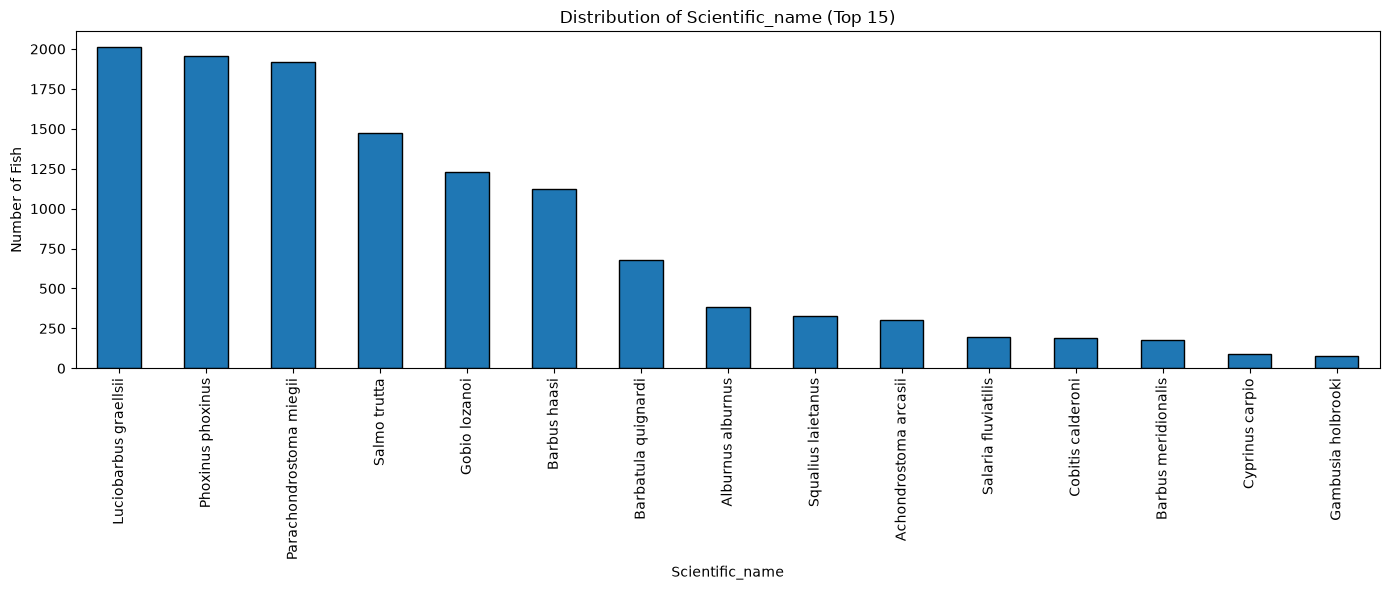

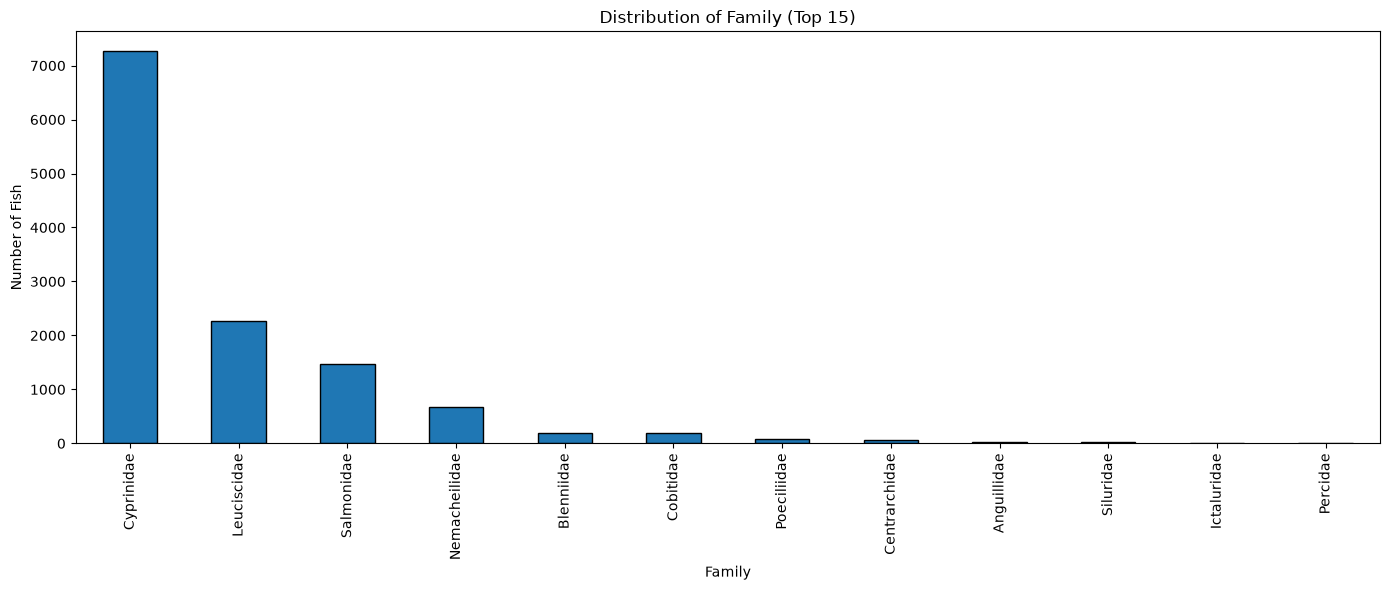


3. CORRELATION MATRIX


,Length_mm,Mass_g,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
Length_mm,1.000000,0.801161,-0.028062,-0.030252,-0.016269,0.033424,-0.004885,0.012952
Mass_g,0.801161,1.000000,-0.002099,0.029955,0.058490,-0.039680,-0.089662,0.035579
TP_mg.l,-0.028062,-0.002099,1.000000,0.214030,0.246139,-0.029279,-0.231384,0.014980
TN_mg.l,-0.030252,0.029955,0.214030,1.000000,0.391838,-0.321936,-0.350960,0.120926
Temp_degree_celcius,-0.016269,0.058490,0.246139,0.391838,1.000000,-0.686575,-0.902181,0.427127
Prec_mm,0.033424,-0.039680,-0.029279,-0.321936,-0.686575,1.000000,0.535828,-0.370648
Alt_m,-0.004885,-0.089662,-0.231384,-0.350960,-0.902181,0.535828,1.000000,-0.476766
IMPRESS,0.012952,0.035579,0.014980,0.120926,0.427127,-0.370648,-0.476766,1.000000



4. CORRELATION HEATMAP


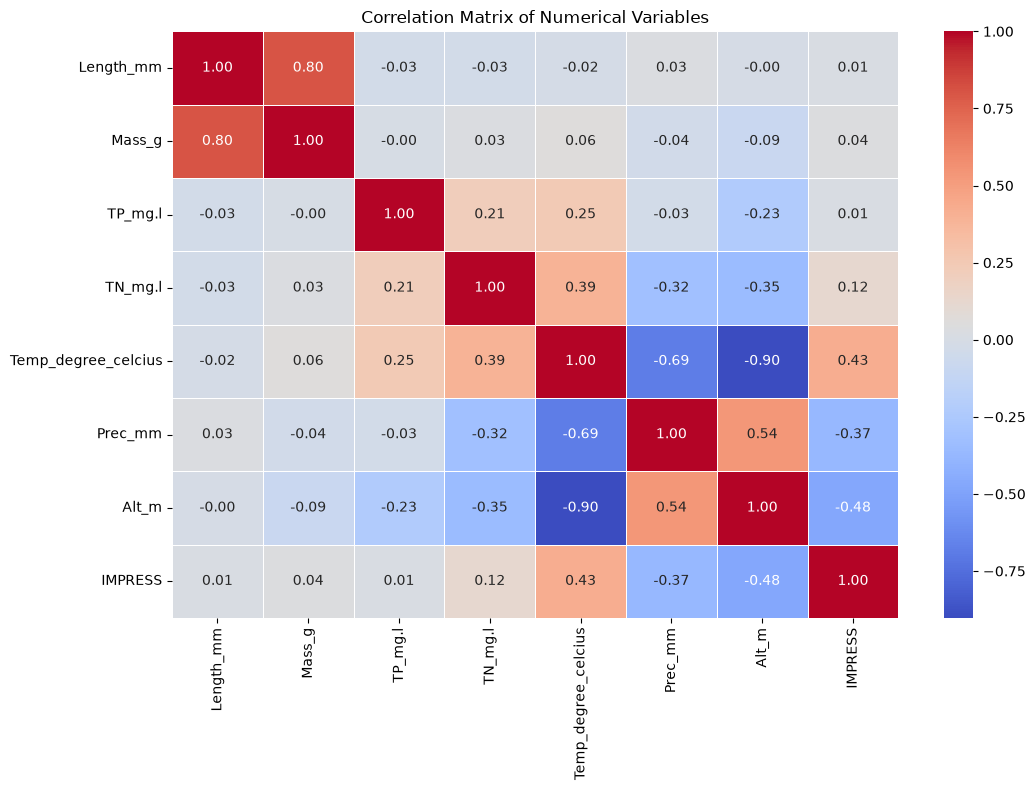


5. CORRELATION WITH THE TARGET: Mass_g


Length_mm              0.801161
Temp_degree_celcius    0.058490
IMPRESS                0.035579
TN_mg.l                0.029955
TP_mg.l               -0.002099
Prec_mm               -0.039680
Alt_m                 -0.089662
Name: Mass_g, dtype: float64

In [31]:
# =====================================================
# STEP 1: DISTRIBUTIONS AND CORRELATION ANALYSIS
# =====================================================

# 1. Define numerical and categorical variables

numerical_columns = [
    "Length_mm",
    "Mass_g",
    "TP_mg.l",
    "TN_mg.l",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "IMPRESS"
]

categorical_columns = [
    "Scientific_name",
    "Family"
]


# 2. Distributions of numerical variables

print("=" * 60)
print("1. DISTRIBUTIONS OF NUMERICAL VARIABLES")
print("=" * 60)

data[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 3. Distributions of categorical variables

print("\n" + "=" * 60)
print("2. DISTRIBUTIONS OF CATEGORICAL VARIABLES")
print("=" * 60)

for column in categorical_columns:

    plt.figure(figsize=(14, 6))

    data[column].value_counts().head(15).plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title(f"Distribution of {column} (Top 15)")
    plt.xlabel(column)
    plt.ylabel("Number of Fish")
    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()


# 4. Correlation matrix

print("\n" + "=" * 60)
print("3. CORRELATION MATRIX")
print("=" * 60)

correlation_matrix = data[numerical_columns].corr()

display(correlation_matrix)


# 5. Correlation heatmap

print("\n" + "=" * 60)
print("4. CORRELATION HEATMAP")
print("=" * 60)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


# 6. Correlation between numerical variables and target

print("\n" + "=" * 60)
print("5. CORRELATION WITH THE TARGET: Mass_g")
print("=" * 60)

target_correlations = (
    correlation_matrix["Mass_g"]
    .drop("Mass_g")
    .sort_values(ascending=False)
)

display(target_correlations)

### Target Distribution and Skewness Analysis

Since this is a regression task, the distribution of the target variable (`Mass_g`) is examined using a histogram and descriptive statistics.

The skewness of the original target is calculated to assess its asymmetry. A logarithmic transformation, `ln(Mass_g)`, is then applied to compare the resulting distribution with the original one.

This analysis helps determine whether the logarithmic transformation makes the target distribution less skewed and more suitable for regression modelling.

1. TARGET VARIABLE: Mass_g
Number of observations: 12288
Minimum mass: 0.1
Maximum mass: 4500.0
Non-positive values: 0


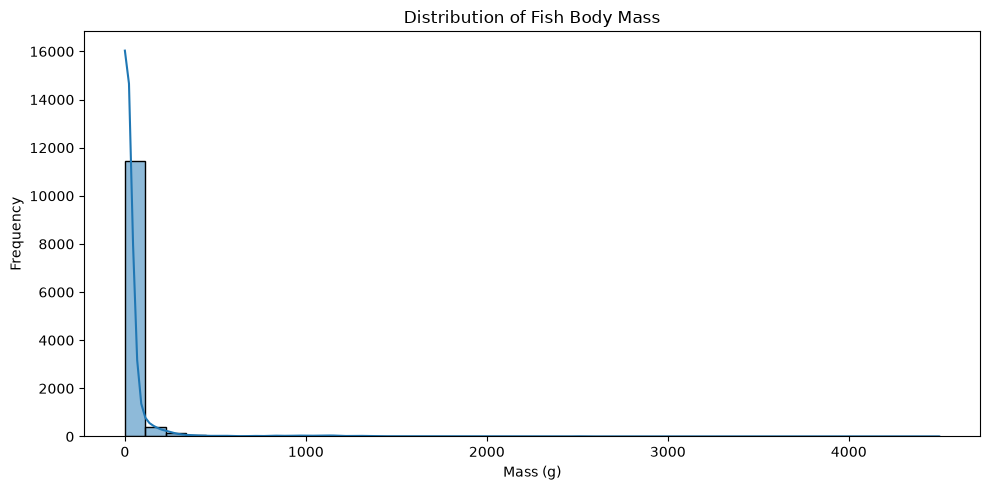


2. ORIGINAL TARGET STATISTICS
count    12288.000000
mean        45.725521
std        180.627982
min          0.100000
25%          2.000000
50%          5.600000
75%         18.925000
max       4500.000000
Name: Mass_g, dtype: float64

Original skewness: 8.357764196828224

3. LOG-TRANSFORMED TARGET STATISTICS
count    12288.000000
mean         1.869214
std          1.807121
min         -2.302585
25%          0.693147
50%          1.722767
75%          2.940481
max          8.411833
Name: ln_Mass, dtype: float64

Log-transformed skewness: 0.41245189303721425


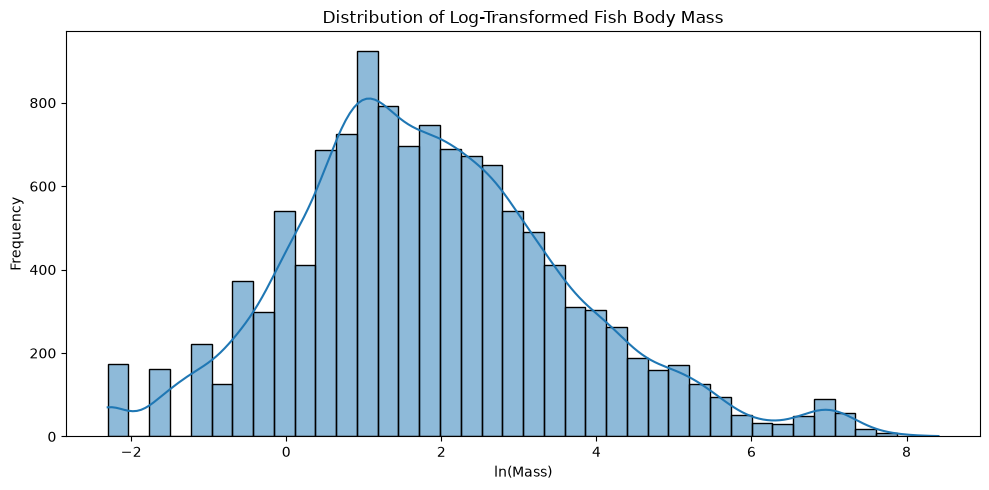


4. SKEWNESS COMPARISON


,Target,Skewness
0,Original Mass_g,8.357764
1,Log-transformed ln(Mass_g),0.412452


In [32]:
# =====================================================
# STEP 1: TARGET DISTRIBUTION AND SKEWNESS
# =====================================================

# 1. Check the target variable

print("=" * 60)
print("1. TARGET VARIABLE: Mass_g")
print("=" * 60)

print("Number of observations:", data["Mass_g"].count())
print("Minimum mass:", data["Mass_g"].min())
print("Maximum mass:", data["Mass_g"].max())

# Check whether all values are positive
non_positive = (data["Mass_g"] <= 0).sum()

print("Non-positive values:", non_positive)


# 2. Original target distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data["Mass_g"],
    bins=40,
    kde=True
)

plt.title("Distribution of Fish Body Mass")
plt.xlabel("Mass (g)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 3. Descriptive statistics and skewness

print("\n" + "=" * 60)
print("2. ORIGINAL TARGET STATISTICS")
print("=" * 60)

print(data["Mass_g"].describe())

original_skewness = data["Mass_g"].skew()

print("\nOriginal skewness:", original_skewness)


# 4. Logarithmic transformation

if non_positive == 0:

    data["ln_Mass"] = np.log(data["Mass_g"])

    log_skewness = data["ln_Mass"].skew()

    print("\n" + "=" * 60)
    print("3. LOG-TRANSFORMED TARGET STATISTICS")
    print("=" * 60)

    print(data["ln_Mass"].describe())

    print("\nLog-transformed skewness:", log_skewness)


    # 5. Distribution after logarithmic transformation

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data["ln_Mass"],
        bins=40,
        kde=True
    )

    plt.title("Distribution of Log-Transformed Fish Body Mass")
    plt.xlabel("ln(Mass)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


    # 6. Compare original and transformed skewness

    skewness_comparison = pd.DataFrame({
        "Target": ["Original Mass_g", "Log-transformed ln(Mass_g)"],
        "Skewness": [original_skewness, log_skewness]
    })

    print("\n" + "=" * 60)
    print("4. SKEWNESS COMPARISON")
    print("=" * 60)

    display(skewness_comparison)

else:
    print("\nLog transformation cannot be applied directly.")
    print("Investigate non-positive mass values first.")

### Structure of Observations and Grouping by Site

The fish dataset contains multiple fish observations collected from the same sites. The variable `Code_ID` identifies each site and links fish observations to their corresponding environmental measurements.

Therefore, observations from the same site may share similar environmental conditions. A random split could place fish from the same site in both training and validation sets, potentially leading to data leakage and overly optimistic performance.

To reduce this risk, GroupKFold by site is used as the reference splitting strategy. All observations belonging to the same site are kept within the same fold.

1. DATASET STRUCTURE
Number of fish observations: 12288
Number of unique sites: 118
Number of fish records with a site ID: 12288

2. FISH OBSERVATIONS PER SITE


,Code_ID,Number_of_Fish
0,1,74
1,2,143
2,3,70
3,4,68
4,5,54
5,6,125
6,7,101
7,8,158
8,9,187
9,10,76



Descriptive statistics:


count    118.000000
mean     104.135593
std       54.331511
min       34.000000
25%       59.500000
50%       91.000000
75%      139.750000
max      263.000000
Name: Number_of_Fish, dtype: float64


Number of sites containing multiple fish: 118
Sites containing only one fish: 0


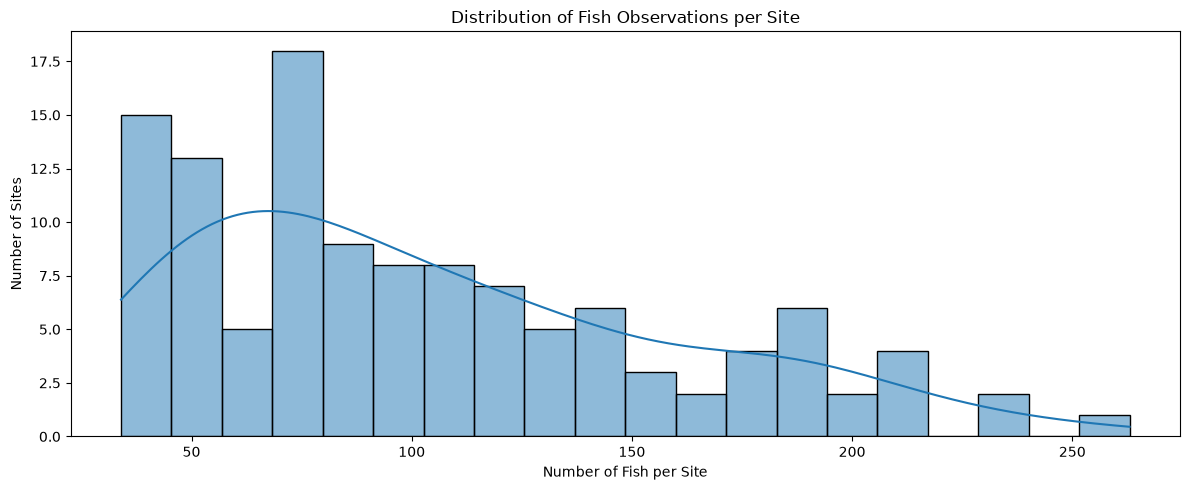


3. SITES WITH THE MOST FISH


,Code_ID,Number_of_Fish
100,101,263
99,100,236
20,21,235
23,24,217
105,106,214
115,116,207
21,22,206
59,60,201
102,103,196
18,19,190


In [33]:
# =====================================================
# STEP 1: STRUCTURE OF OBSERVATIONS AND GROUPING BY SITE
# =====================================================

# 1. General information about sites

print("=" * 60)
print("1. DATASET STRUCTURE")
print("=" * 60)

print("Number of fish observations:", len(fish_data))
print("Number of unique sites:", fish_data["Code_ID"].nunique())
print("Number of fish records with a site ID:",
      fish_data["Code_ID"].notna().sum())


# 2. Number of fish collected at each site

fish_per_site = (
    fish_data.groupby("Code_ID")
    .size()
    .reset_index(name="Number_of_Fish")
)

print("\n" + "=" * 60)
print("2. FISH OBSERVATIONS PER SITE")
print("=" * 60)

display(fish_per_site.head(10))

print("\nDescriptive statistics:")
display(fish_per_site["Number_of_Fish"].describe())


# 3. Check whether observations are repeated within sites

sites_with_multiple_fish = (
    fish_per_site["Number_of_Fish"] > 1
).sum()

print("\nNumber of sites containing multiple fish:",
      sites_with_multiple_fish)

print("Sites containing only one fish:",
      (fish_per_site["Number_of_Fish"] == 1).sum())


# 4. Visualize the number of fish per site

plt.figure(figsize=(12, 5))

sns.histplot(
    fish_per_site["Number_of_Fish"],
    bins=20,
    kde=True
)

plt.title("Distribution of Fish Observations per Site")
plt.xlabel("Number of Fish per Site")
plt.ylabel("Number of Sites")

plt.tight_layout()
plt.show()


# 5. Identify the sites with the most fish

print("\n" + "=" * 60)
print("3. SITES WITH THE MOST FISH")
print("=" * 60)

display(
    fish_per_site.sort_values(
        by="Number_of_Fish",
        ascending=False
    ).head(10)
)

### STEP 2: Cleaning and Preparation
### 2.1: Duplicate Removal, Data Types, Units, and Feature Creation

Exact duplicate records are identified and removed from the fish dataset. The stream dataset is also checked for duplicate records.

The data types of the variables are reviewed to ensure that numerical and categorical variables are correctly represented. Measurement units are checked using the dataset documentation.

The fish and stream datasets are then merged using `Code_ID`, which identifies the sampling site. The merge is validated to ensure that each fish observation is associated with the correct site information.

Useful transformed variables are created when appropriate. The target variable is log-transformed as required by the regression task. No observations are removed solely because they have extreme values.


In [34]:
# =====================================================
# STEP 2.1: CLEANING AND PREPARATION
# =====================================================

# 1. Create copies of the original datasets

fish_clean = fish_data.copy()
stream_clean = stream_data.copy()


# 2. Check and remove exact duplicate records

print("=" * 60)
print("1. DUPLICATE REMOVAL")
print("=" * 60)

fish_duplicates = fish_clean.duplicated().sum()
stream_duplicates = stream_clean.duplicated().sum()

print("Fish duplicates before cleaning:", fish_duplicates)
print("Stream duplicates before cleaning:", stream_duplicates)

fish_clean = fish_clean.drop_duplicates().copy()
stream_clean = stream_clean.drop_duplicates().copy()

print("\nFish records after cleaning:", len(fish_clean))
print("Stream records after cleaning:", len(stream_clean))

print("Remaining fish duplicates:", fish_clean.duplicated().sum())
print("Remaining stream duplicates:", stream_clean.duplicated().sum())


# 3. Correct and verify data types

print("\n" + "=" * 60)
print("2. DATA TYPES")
print("=" * 60)

# Numerical variables in the fish dataset
fish_numeric = ["Code_ID", "Length_mm", "Mass_g"]

for column in fish_numeric:
    fish_clean[column] = pd.to_numeric(
        fish_clean[column],
        errors="raise"
    )

# Categorical variables in the fish dataset
fish_categorical = [
    "Stream", "Location", "Family",
    "Genus", "Species", "Scientific_name"
]

for column in fish_categorical:
    fish_clean[column] = fish_clean[column].astype("category")


# Numerical variables in the stream dataset
stream_numeric = [
    "Code_ID", "Lat_degree", "Long_degree",
    "Day", "Month", "Year", "Fish_number",
    "SA_m2", "TP_mg.l", "TN_mg.l",
    "Temp_degree_celcius", "Prec_mm",
    "Alt_m", "IMPRESS"
]

for column in stream_numeric:
    stream_clean[column] = pd.to_numeric(
        stream_clean[column],
        errors="raise"
    )

# Categorical variables in the stream dataset
stream_categorical = ["Stream", "Location", "Source"]

for column in stream_categorical:
    stream_clean[column] = stream_clean[column].astype("category")


print("Fish dataset types:")
display(fish_clean.dtypes)

print("\nStream dataset types:")
display(stream_clean.dtypes)


# 4. Verify site identifiers before merging

print("\n" + "=" * 60)
print("3. SITE IDENTIFIER CHECK")
print("=" * 60)

print("Unique fish site IDs:", fish_clean["Code_ID"].nunique())
print("Unique stream site IDs:", stream_clean["Code_ID"].nunique())

print("Duplicate site IDs in stream dataset:",
      stream_clean["Code_ID"].duplicated().sum())


# 5. Merge fish and environmental information

environmental_columns = [
    "Code_ID",
    "TP_mg.l",
    "TN_mg.l",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "IMPRESS"
]

data = fish_clean.merge(
    stream_clean[environmental_columns],
    on="Code_ID",
    how="left",
    validate="many_to_one"
)

print("\n" + "=" * 60)
print("4. MERGED DATASET")
print("=" * 60)

print("Merged dataset shape:", data.shape)
print("Missing values after merging:")
display(data.isnull().sum())


# 6. Create the logarithmic target variable

print("\n" + "=" * 60)
print("5. TARGET TRANSFORMATION")
print("=" * 60)

if (data["Mass_g"] <= 0).any():
    raise ValueError(
        "Non-positive Mass_g values found. "
        "Investigate them before applying the logarithm."
    )

data["ln_Mass"] = np.log(data["Mass_g"])

print("Log-transformed target created: ln_Mass")
display(data[["Mass_g", "ln_Mass"]].head())


# 7. Final verification

print("\n" + "=" * 60)
print("6. FINAL CLEANING CHECK")
print("=" * 60)

print("Final dataset shape:", data.shape)
print("Remaining exact duplicate rows:", data.duplicated().sum())
print("Total missing values:", data.isnull().sum().sum())

display(data.head())

1. DUPLICATE REMOVAL
Fish duplicates before cleaning: 883
Stream duplicates before cleaning: 0

Fish records after cleaning: 11405
Stream records after cleaning: 118
Remaining fish duplicates: 0
Remaining stream duplicates: 0

2. DATA TYPES
Fish dataset types:


Code_ID               int64
Stream             category
Location           category
Family             category
Genus              category
Species            category
Scientific_name    category
Length_mm             int64
Mass_g              float64
dtype: object


Stream dataset types:


Code_ID                   int64
Stream                 category
Location               category
Lat_degree              float64
Long_degree             float64
Source                 category
Day                       int64
Month                     int64
Year                      int64
Fish_number               int64
SA_m2                   float64
TP_mg.l                 float64
TN_mg.l                 float64
Temp_degree_celcius     float64
Prec_mm                   int64
Alt_m                   float64
IMPRESS                 float64
dtype: object


3. SITE IDENTIFIER CHECK
Unique fish site IDs: 118
Unique stream site IDs: 118
Duplicate site IDs in stream dataset: 0

4. MERGED DATASET
Merged dataset shape: (11405, 15)
Missing values after merging:


Code_ID                0
Stream                 0
Location               0
Family                 0
Genus                  0
Species                0
Scientific_name        0
Length_mm              0
Mass_g                 0
TP_mg.l                0
TN_mg.l                0
Temp_degree_celcius    0
Prec_mm                0
Alt_m                  0
IMPRESS                0
dtype: int64


5. TARGET TRANSFORMATION
Log-transformed target created: ln_Mass


,Mass_g,ln_Mass
0,1700.0,7.438384
1,1220.0,7.106606
2,1040.0,6.946976
3,139.9,4.940928
4,133.0,4.890349



6. FINAL CLEANING CHECK
Final dataset shape: (11405, 16)
Remaining exact duplicate rows: 0
Total missing values: 0


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS,ln_Mass
0,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,442,1700.0,0.1,8.38,12.5,727,454.68,2.0,7.438384
1,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,405,1220.0,0.1,8.38,12.5,727,454.68,2.0,7.106606
2,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,373,1040.0,0.1,8.38,12.5,727,454.68,2.0,6.946976
3,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,199,139.9,0.1,8.38,12.5,727,454.68,2.0,4.940928
4,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,225,133.0,0.1,8.38,12.5,727,454.68,2.0,4.890349


### 2.2: Encoding Categorical Variables

The species variable is categorical and has no natural order. Therefore, One-Hot Encoding is selected to convert species categories into numerical binary features.

Each species is represented by a separate binary column. The encoder is configured to handle previously unseen categories.

To prevent data leakage, the encoder will be fitted only on the training data as part of the preprocessing pipeline.

In [35]:
# =====================================================
# STEP 2.2: ENCODING CATEGORICAL VARIABLES
# =====================================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Identify the categorical variable
categorical_features = ["Scientific_name"]

# 2. Create the One-Hot Encoder
one_hot_encoder = OneHotEncoder(
    handle_unknown="ignore"
)

# 3. Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            one_hot_encoder,
            categorical_features
        )
    ],
    remainder="passthrough"
)

# 4. Verify the categorical variable
print("Categorical variables selected:")
print(categorical_features)

print("\nNumber of unique species:",
      data["Scientific_name"].nunique())

print("\nSpecies examples:")
display(data["Scientific_name"].value_counts().head())

print("\nOne-Hot Encoder configured successfully.")
print("Encoding will be fitted on training data only.")

Categorical variables selected:
['Scientific_name']

Number of unique species: 24

Species examples:


Scientific_name
Luciobarbus graellsii      1964
Parachondrostoma miegii    1773
Phoxinus phoxinus          1708
Salmo trutta               1445
Gobio lozanoi              1152
Name: count, dtype: int64


One-Hot Encoder configured successfully.
Encoding will be fitted on training data only.


### 2.3: Handling Missing Values and Outliers

Missing values and potential outliers are examined before making any cleaning decisions.

Missing values are not removed automatically. Their number and distribution are inspected to determine whether imputation is necessary.

Potential outliers are identified using the Interquartile Range (IQR) method. However, extreme observations are not automatically removed because they may represent genuine fish measurements or environmental conditions.

Any imputation or preprocessing parameters learned from the data will be fitted on the training data only to avoid data leakage.

In [36]:
# =====================================================
# STEP 2.3: MISSING VALUES AND OUTLIERS
# =====================================================

# 1. Check missing values

print("=" * 60)
print("1. MISSING VALUES ANALYSIS")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Missing Values": data.isnull().sum(),
    "Percentage (%)": data.isnull().mean() * 100
})

display(missing_summary)


# 2. Identify numerical variables for outlier analysis

numerical_features = [
    "Length_mm",
    "Mass_g",
    "TP_mg.l",
    "TN_mg.l",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "IMPRESS"
]


# 3. Calculate IQR bounds and detect potential outliers

print("\n" + "=" * 60)
print("2. POTENTIAL OUTLIERS USING IQR")
print("=" * 60)

outlier_results = []

for column in numerical_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_results.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage (%)":
            outlier_count / len(data) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)


# 4. Display examples of potential outliers

print("\n" + "=" * 60)
print("3. EXAMPLES OF POTENTIAL OUTLIERS")
print("=" * 60)

for column in numerical_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\n{column}:")
    display(outliers[["Code_ID", column]].head(5))


# 5. Final verification

print("\n" + "=" * 60)
print("4. CLEANING DECISION")
print("=" * 60)

print("Total missing values:", data.isnull().sum().sum())
print("Total rows:", len(data))

print("No observations were removed based on IQR.")
print("Potential outliers are retained for further investigation.")

1. MISSING VALUES ANALYSIS


,Missing Values,Percentage (%)
Code_ID,0,0.0
Stream,0,0.0
Location,0,0.0
Family,0,0.0
Genus,0,0.0
Species,0,0.0
Scientific_name,0,0.0
Length_mm,0,0.0
Mass_g,0,0.0
TP_mg.l,0,0.0



2. POTENTIAL OUTLIERS USING IQR


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Length_mm,58.00,119.00,61.00,-33.500,210.500,808,7.084612
1,Mass_g,2.20,21.00,18.80,-26.000,49.200,1586,13.906181
2,TP_mg.l,0.09,0.14,0.05,0.015,0.215,1890,16.571679
3,TN_mg.l,2.20,12.20,10.00,-12.800,27.200,422,3.700132
4,Temp_degree_celcius,11.70,13.70,2.00,8.700,16.700,213,1.867602
5,Prec_mm,490.00,767.00,277.00,74.500,1182.500,0,0.000000
6,Alt_m,322.84,627.71,304.87,-134.465,1085.015,94,0.824200
7,IMPRESS,4.05,10.00,5.95,-4.875,18.925,0,0.000000



3. EXAMPLES OF POTENTIAL OUTLIERS

Length_mm:


,Code_ID,Length_mm
0,1,442
1,1,405
2,1,373
4,1,225
204,3,235


... (11 outputs left out)

,Code_ID,Alt_m
4571,45,1293.66
4572,45,1293.66
4573,45,1293.66
4574,45,1293.66
4575,45,1293.66



IMPRESS:


,Code_ID,IMPRESS



4. CLEANING DECISION
Total missing values: 0
Total rows: 11405
No observations were removed based on IQR.
Potential outliers are retained for further investigation.


No missing values were found in the merged dataset. Potential outliers were identified using the IQR method, but they were retained because extreme values may represent genuine biological measurements or environmental conditions. No observations were removed solely based on statistical outlier detection.

### 2.4: Preventing Data Leakage Using a Pipeline

All preprocessing operations that learn parameters from the data must be fitted using training data only.

Standardization, categorical encoding, and missing-value imputation (if required) are included in a preprocessing pipeline.

A Scikit-learn Pipeline is used to combine preprocessing and the SVR model. This ensures that, during cross-validation, preprocessing parameters are learned independently from each training fold and then applied to its validation fold.

The test data will remain separate and will not be used during preprocessing or hyperparameter tuning.

In [38]:
# =====================================================
# STEP 2.4: PREPROCESSING PIPELINE
# =====================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.impute import SimpleImputer


# 1. Define input features

numerical_features = [
    "Length_mm",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "TP_mg.l",
    "TN_mg.l",
    "IMPRESS"
]

categorical_features = [
    "Scientific_name"
]


# 2. Numerical preprocessing

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# 3. Categorical preprocessing

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# 4. Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)


# 5. Create the complete SVR pipeline

svr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVR(kernel="rbf", epsilon=0.1))
])


# 6. Prepare X, y, and groups

X = data[numerical_features + categorical_features]

y = data["ln_Mass"]

groups = data["Code_ID"]


# 7. Display pipeline structure

print("Preprocessing pipeline:")
display(svr_pipeline)

print("\nNumber of input features before encoding:", X.shape[1])
print("Number of observations:", X.shape[0])
print("Number of unique sites:", groups.nunique())

print("\nPipeline created successfully.")

Preprocessing pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def


Number of input features before encoding: 8
Number of observations: 11405
Number of unique sites: 118

Pipeline created successfully.
